# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

## Preliminares

In [35]:
import pandas as pd

from src.modeling import (
    cargar_datos_clean, filtrar_pares_restantes, separar_datos_live,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots, top_correlaciones_objetivo
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 965 entries, 2007-05-07 to 2026-11-02
Columns: 107 entries, EURUSD_intra_weekly to STLFSI_delta_20d_yeo
dtypes: float64(107)
memory usage: 814.2 KB


In [36]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

## Analisis de variables

In [37]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "_Volume_zscore_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
Oil_Volume_zscore_lag1_yeo,965.0,2.945255e-17,1.000519,-3.623350,-0.603941,-0.001785,0.687805,5.793489
Gold_Volume_zscore_lag1_yeo,965.0,2.577098e-17,1.000519,-9.994021,-0.265696,-0.182292,0.211483,3.411065
SPY_Volume_zscore_lag1_yeo,965.0,-3.681569e-18,1.000519,-4.689768,-0.581379,-0.015216,0.598002,4.647720


In [38]:
# Asimetrias general
mostrar_asimetrias(df_clean)

USDCHF_vol_ratio_lag1               2.397832
VIX_level                           2.363348
USDCAD_accel_diff_zscore_lag1       2.111020
USDJPY_vol_ratio_lag1               2.017335
USDCAD_variance_lag1_log            2.015760
EURUSD_vol_ratio_lag1               1.737213
AUDUSD_vol_ratio_lag1               1.656826
GBPUSD_vol_ratio_lag1               1.644817
EURUSD_return_skew_lag1             1.592432
USDCAD_vol_ratio_lag1_log           1.370777
Oil_return_skew_lag1                1.162347
USDCHF_variance_lag1_log            1.079099
USDCHF_accel_diff_zscore_lag1       0.990184
USDCAD_ret_diff_zscore_lag1         0.970730
Oil_vol_directional_lag1_log        0.872044
EURUSD_open_gap_zscore_yeo          0.819238
Oil_variance_lag1_log               0.790460
GBPUSD_variance_lag1_log            0.618789
GBPUSD_open_gap_zscore_yeo          0.593741
SPY_acceleration_zscore_lag1        0.592599
AUDUSD_sma15_pct_diff_sma50_lag1    0.564662
AUDUSD_vol_directional_lag1_log     0.557991
USDJPY_sma

In [39]:
# Asimetria por grupo
cadena = "_open_gap_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

EURUSD_open_gap_zscore_yeo    0.819238
GBPUSD_open_gap_zscore_yeo    0.593741
USDCHF_open_gap_zscore_yeo    0.485674
AUDUSD_open_gap_zscore_yeo    0.280930
GBPUSD_open_gap_skew_yeo      0.129145
USDCHF_open_gap_skew_yeo     -0.006502
AUDUSD_open_gap_skew_yeo     -0.040407
USDJPY_open_gap_skew_yeo     -0.139568
USDCAD_open_gap_skew_yeo     -0.181340
EURUSD_open_gap_skew_yeo     -0.207086
USDJPY_open_gap_zscore_yeo   -0.438598
USDCAD_open_gap_zscore_yeo   -3.357598


Cont


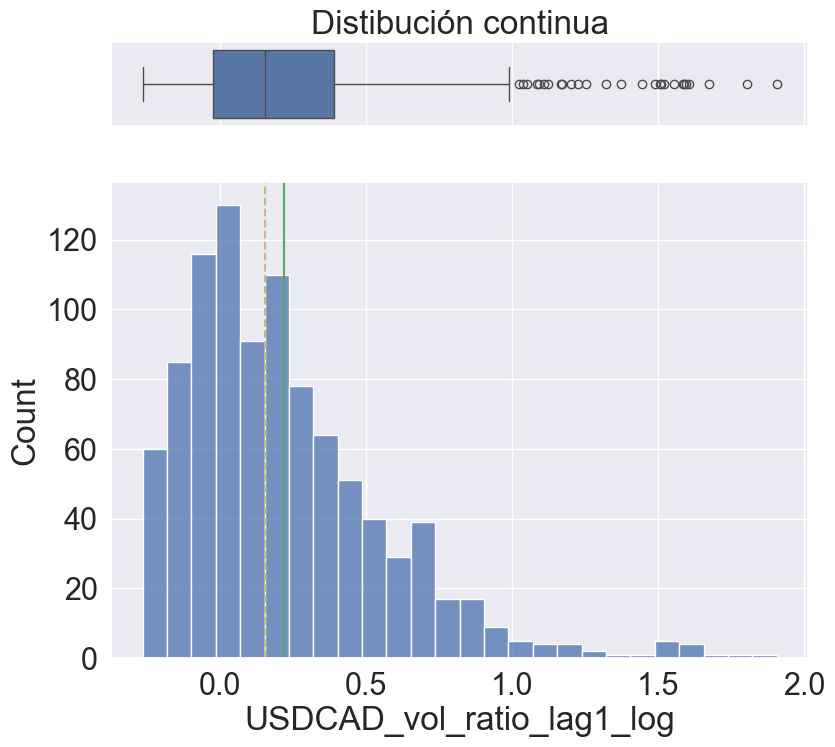

In [40]:
# Visualizar columna
col = 'USDCAD_vol_ratio_lag1_log'
pintar_columna(df_clean[col])

## Correlaciones

In [41]:
# Tabla de Correlaciones general
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
1362,AUDUSD_sma15_pct_diff_sma50_lag1,USDCAD_sma15_pct_diff_sma50_lag1,0.833690
959,USDCHF_sma15_pct_diff_sma50_lag1,EURUSD_sma15_pct_diff_sma50_lag1,0.785299
2411,USDCHF_variance_lag1_log,EURUSD_variance_lag1_log,0.750166
527,USDCAD_acceleration_zscore_lag1,USDCAD_return_zscore_lag1,0.748642
915,USDCHF_range10_position_lag1,EURUSD_range10_position_lag1,0.745986
779,USDCHF_acceleration_zscore_lag1,USDCHF_return_zscore_lag1,0.728386
3132,AUDUSD_vol_directional_lag1_log,AUDUSD_range10_position_lag1,0.727443
2713,EURUSD_vol_directional_lag1_log,EURUSD_range10_position_lag1,0.725662
789,USDCHF_ret_diff_zscore_lag1,EURUSD_ret_diff_zscore_lag1,0.724015
1890,SPY_acceleration_zscore_lag1,SPY_return_zscore_lag1,0.717855


In [42]:
# Correlaciones con la variable objetivo continua
simbolo_objetivo = 'EURUSD'
objetivo = f"{simbolo_objetivo}_intra_weekly"

top_correlaciones_objetivo(df=df_clean, target_col=objetivo)

,Variable,Correlación
0,USDCHF_intra_weekly,-0.674737
1,GBPUSD_intra_weekly,0.631469
2,AUDUSD_intra_weekly,0.489586
3,USDJPY_intra_weekly,-0.347518
4,USDCAD_intra_weekly,-0.342701
5,USDCHF_return_zscore_lag1,0.106312
6,USDCHF_acceleration_zscore_lag1,0.087926
7,GBPUSD_variance_lag1_log,0.083817
8,USDCHF_spread_zscore_lag1_yeo,-0.078262
9,USDCAD_variance_lag1_log,0.073626


## Analisis de label categorica

In [43]:
# Filtrar pares restantes
df_filtrado = filtrar_pares_restantes(df_clean,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df_filtrado.index.max()
df_train, df_live = separar_datos_live(df=df_filtrado, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles

objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker EURUSD ---
   categoria  lim_inferior  lim_superior
0          1     -0.039486     -0.003891
1          2     -0.003891      0.005253
2          3      0.005253      0.045143


In [44]:
df_train[objetivo_cat].value_counts()

EURUSD_intra_weekly_cat
3    322
1    321
2    321
Name: count, dtype: int64



In [45]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]


pintar_violin_plots(
    df=df_train,
    numeric_cols=numeric_cols,
    target_col=target_col
)